Here is a simple example code for device fitting using a multilayer perceptron model.
This code demonstrates the implementation of a Multilayer Perceptron (MLP) using PyTorch, a popular deep learning framework. Let's break down the key components of this code.

In [1]:
import os
import sys
import json

import torch
import torch.nn as nn
from torchvision import transforms, datasets, utils
import matplotlib.pyplot as plt
import numpy as np
import torch.optim as optim
from torch.optim.lr_scheduler import ReduceLROnPlateau
import pandas as pd
from tqdm import tqdm
import random
from sklearn.model_selection import train_test_split, GridSearchCV, ParameterGrid
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import mean_squared_error
from sklearn.preprocessing import StandardScaler
from torch.utils.data import TensorDataset, DataLoader

from model import MLP

This code defines a Multilayer Perceptron (MLP) neural network using PyTorch's nn.Module.
self.features defines the sequential layers of the neural network using nn.Sequential().
Here we define a 3-layer MLP.
nn.Linear(3, 30): The first layer consists of 3 input neurons and 30 neurons in the hidden layer. It performs a linear transformation (fully connected layer) from 3 input features to 30 neurons.
nn.ReLU(inplace=True): Applies a Rectified Linear Unit (ReLU) activation function to introduce non-linearity after the first linear transformation.
nn.Linear(30, 10): The second layer comprises 30 input neurons and 10 neurons in the hidden layer, followed by another ReLU activation.
nn.Linear(10,1): The final layer has 10 input neurons and 1 output neuron, producing the final output of the MLP.

The forward method defines the forward pass through the network.

In [2]:
class FatGCN(nn.Module):
    def __init__(self, input_dim, hidden_dim, output_dim):
        super(FatGCN, self).__init__()
        self.fc1 = nn.Linear(input_dim, hidden_dim)
        self.fc2 = nn.Linear(hidden_dim, hidden_dim)
        self.fc3 = nn.Linear(hidden_dim, output_dim)
        self.relu = nn.ReLU()

    def forward(self, x):
        x = self.relu(self.fc1(x))
        x = self.relu(self.fc2(x))
        x = self.fc3(x)
        return x


The code snippet demonstrates the selection of the computational device for running the MLP (Multilayer Perceptron) network.
Device Allocation:
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu"): This line of code assigns the computational device to the variable device. If a GPU is available, it selects the GPU (cuda:0); otherwise, it defaults to the CPU (cpu).
Printing Device Information:
print("using {} device.".format(device)): This prints a message indicating the device being utilized for computation.

In [3]:
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print("using {} device.".format(device))

using cpu device.


The code snippet demonstrates reading data from an Excel file into a Python environment using the Pandas library.
Excel File Import:
excel_file = '../data/carbon/pfet.xlsx': Specifies the file path (pfet.xlsx) of the Excel file containing the data.
Pandas DataFrame Creation:
df = pd.read_excel(excel_file): Utilizes Pandas' read_excel function to load the Excel file into a Pandas DataFrame named df. This function reads the Excel file's contents and stores them in a tabular format.
Data Verification:
print(df.head()): Displays the first few rows of the loaded DataFrame using the head() method. This step helps verify the successful import of data by showing the initial rows of the DataFrame, ensuring that the data is correctly read and structured.

In [4]:
#Excel File Import
csv_file = 'Silicon_Dataset.csv'
df = pd.read_csv(csv_file)
df = df.apply(pd.to_numeric)

print(df.head())

    Lg  Lch    Tox          Nsub         PeakV  Vds       Vgs            Id
0  0.1  0.2  0.008  1.000000e+18  6.000000e+20  0.2 -1.000000  3.220000e-16
1  0.1  0.2  0.008  1.000000e+18  6.000000e+20  0.2 -0.974747  3.220000e-16
2  0.1  0.2  0.008  1.000000e+18  6.000000e+20  0.2 -0.949495  3.210000e-16
3  0.1  0.2  0.008  1.000000e+18  6.000000e+20  0.2 -0.924242  3.230000e-16
4  0.1  0.2  0.008  1.000000e+18  6.000000e+20  0.2 -0.898990  3.230000e-16


This code snippet focuses on data preparation steps necessary before training the Multilayer Perceptron (MLP) model.
Input and Output Extraction:
Specifies the columns representing input features based on their column names in the dataset.
Defines the output column ('ids') indicating the target output (e.g., current) from the dataset.
Conversion to PyTorch Tensors:
Converts the selected input columns and output column into PyTorch tensors. This step transforms the input data into a format suitable for feeding into the neural network.
Data Transformation:
Take the logarithm of the output data to narrow the data range. This transformation might be employed to normalize or preprocess the output data, ensuring better convergence during training or meeting specific requirements of the model.

In [5]:

# Assuming 'df' is your DataFrame and 'Id' is the target column
input_columns = ['Lg', 'Lch', 'Tox', 'Nsub', 'PeakV', 'Vds', 'Vgs']
output_column = 'Id'

# Prepare the data
X = df[input_columns].values
Y = df[output_column].values

# Take the logarithm base 10 of the output data
Y = np.log10(Y)

print(Y)

[-15.49214413 -15.49214413 -15.49349497 ... -13.91721463 -13.91364017
 -13.91364017]


This section of code mainly used do feature selection and show the importance of each different feature's relationship and importance between the factors.

In [6]:
# # Splitting the data into train and test sets
# X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=42)

# # Train a Random Forest Regressor model
# rf_model = RandomForestRegressor(random_state=42)
# rf_model.fit(X_train, Y_train)

# # Compute the baseline Mean Squared Error
# Y_pred = rf_model.predict(X_test)
# baseline_mse = mean_squared_error(Y_test, Y_pred)
# print(f"Baseline Mean Squared Error: {baseline_mse:.4f}")

# # Get feature importances
# feature_importances = rf_model.feature_importances_

# # Display feature importance
# feature_names = X_test.columns.tolist()
# importance_df = pd.DataFrame({'Feature': feature_names, 'Importance': feature_importances})
# importance_df = importance_df.sort_values(by='Importance', ascending=False)

# print(importance_df)

# # Plot feature importance
# plt.figure(figsize=(10, 6))
# plt.barh(importance_df['Feature'], importance_df['Importance'])
# plt.xlabel('Importance')
# plt.ylabel('Feature')
# plt.title('Feature Importance')
# plt.gca().invert_yaxis()
# plt.show()

This section of the code snippet focuses on partitioning the available data into separate sets for training and testing the MLP (Multilayer Perceptron) model.
Splitting the Dataset:
These calculations aim to appropriately divide the dataset into two distinct portions:
Training Set: Comprising 90% of the data, reserved for training the MLP model. It includes input-output pairs used to optimize the model's parameters.
Testing Set: Consisting of the remaining 10% of the data. This set remains unseen during training and is employed solely for evaluating the model's performance on unseen data, assessing its generalization capability.

In [7]:
# Pick the first 10000 samples
sample_num = 10000
X = X[:sample_num]
Y = Y[:sample_num]

# Normalize the data
scaler_X = StandardScaler()
scaler_Y = StandardScaler()
X = scaler_X.fit_transform(X)
Y = scaler_Y.fit_transform(Y.reshape(-1, 1)).flatten()

# Split the data into training and testing sets
# Split the data into training and testing sets without randomization
split_index = int(0.8 * sample_num)
X_train, X_test = X[:split_index], X[split_index:]
y_train, y_test = Y[:split_index], Y[split_index:]

# Convert the data to PyTorch tensors
X_train = torch.tensor(X_train, dtype=torch.float32)
y_train = torch.tensor(y_train, dtype=torch.float32)
X_test = torch.tensor(X_test, dtype=torch.float32)
y_test = torch.tensor(y_test, dtype=torch.float32)

# Create TensorDataset and DataLoader
train_dataset = torch.utils.data.TensorDataset(X_train, y_train)
test_dataset = torch.utils.data.TensorDataset(X_test, y_test)
train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=32, shuffle=True)
test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=32)


This part of the code is responsible for constructing specific datasets—both for training and testing the MLP (Multilayer Perceptron) model.
Constructs the training dataset and forms the testing dataset (test_dataset) by packing the remaining input-output pairs not included in the training set.

This section of the code focuses on setting up data loaders, essential components used to manage and facilitate the training and testing processes within the MLP.
Defining Batch Size:
batch_size = 32: Specifies the batch size, indicating the number of samples that the model will process in each iteration during training or testing. It's a hyperparameter selected to balance computational efficiency and model learning.
Creating Training Data Loader:
Constructs a training data loader (train_loader) using PyTorch's DataLoader. This loader takes the previously created training dataset (train_dataset) and organizes it into batches of size batch_size. The shuffle=True parameter randomly shuffles the samples within each batch, enhancing model learning by providing diverse sample sequences.
Creating Testing Data Loader:
Constructs a testing data loader (test_loader) in a similar manner to the training loader. It takes the testing dataset (test_dataset) and organizes it into batches of the specified batch_size.

In [8]:
# creating data loader
batch_size = 32
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size)



In [ ]:
# Initialize the FatGCN model
input_dim = X_train.shape[1]
hidden_dim = 64
output_dim = 1
net = FatGCN(input_dim, hidden_dim, output_dim).to(device)


net.to(device)
# Define the loss function and optimizer
loss_function = nn.MSELoss()
optimizer = optim.Adam(net.parameters(), lr=0.0001)


In [10]:
# Training loop
epochs = 100
save_path = './FatGCN.pth'
best_val_mse = float('inf')
train_steps = len(train_loader)
val_mse_list = []  # List to store val_mse values

for epoch in range(epochs):
    # Train
    net.train()    
    running_loss = 0.0
    train_bar = tqdm(train_loader, file=sys.stdout)
    for step, data in enumerate(train_bar):
        input_vari, output_tar = data
        optimizer.zero_grad()
        outputs = net(input_vari.to(device))
        loss = loss_function(outputs, output_tar.to(device))
        loss.backward()
        optimizer.step()

        # Print statistics
        running_loss += loss.item()
        train_bar.desc = "train epoch[{}/{}] loss:{:.3f}".format(epoch + 1, epochs, loss)
    
    # Validate
    net.eval()
    mse_sum = 0.0
    y_test = []
    y_pred = []
    with torch.no_grad():
        val_bar = tqdm(test_loader, file=sys.stdout)
        for val_data in val_bar:
            val_input, val_output = val_data
            outputs = net(val_input.to(device))
            mse = loss_function(outputs, val_output.to(device))
            mse_sum += mse.item() * val_input.size(0)
            y_test.extend(val_output.cpu().numpy())
            y_pred.extend(outputs.cpu().numpy())

    val_mse = mse_sum / len(test_loader.dataset)
    val_mse_list.append(val_mse)  # Store val_mse value
    print('[epoch %d] train_loss: %.3f  val_mse: %.6f' %
          (epoch + 1, running_loss / train_steps, val_mse))

    # Save the best model
    if val_mse < best_val_mse:
        best_val_mse = val_mse
        torch.save(net.state_dict(), save_path)


train epoch[1/100] loss:1.149:  13%|█▎        | 32/250 [00:00<00:00, 282.45it/s]

c:\Python\Python311\Lib\site-packages\torch\nn\modules\loss.py:608: UserWarning: Using a target size (torch.Size([32])) that is different to the input size (torch.Size([32, 1])). This will likely lead to incorrect results due to broadcasting. Please ensure they have the same size.
  return F.mse_loss(input, target, reduction=self.reduction)


100%|██████████| 63/63 [00:00<00:00, 1524.52it/s]

c:\Python\Python311\Lib\site-packages\torch\nn\modules\loss.py:608: UserWarning: Using a target size (torch.Size([16])) that is different to the input size (torch.Size([16, 1])). This will likely lead to incorrect results due to broadcasting. Please ensure they have the same size.
  return F.mse_loss(input, target, reduction=self.reduction)



[epoch 1] train_loss: 1.007  val_mse: 0.960574
100%|██████████| 63/63 [00:00<00:00, 1589.24it/s]
[epoch 2] train_loss: 1.006  val_mse: 0.953308
100%|██████████| 63/63 [00:00<00:00, 1336.91it/s]
[epoch 3] train_loss: 1.006  val_mse: 0.949851
100%|██████████| 63/63 [00:00<00:00, 1587.78it/s]
[epoch 4] train_loss: 1.005  val_mse: 0.940377
100%|██████████| 63/63 [00:00<00:00, 2416.38it/s]
[epoch 5] train_loss: 1.006  val_mse: 0.935560
100%|██████████| 63/63 [00:00<00:00, 1804.16it/s]
[epoch 6] train_loss: 1.005  val_mse: 0.945551
100%|██████████| 63/63 [00:00<00:00, 1532.03it/s]
[epoch 7] train_loss: 1.005  val_mse: 0.941729
100%|██████████| 63/63 [00:00<00:00, 1827.01it/s]
[epoch 8] train_loss: 1.005  val_mse: 0.951685
100%|██████████| 63/63 [00:00<00:00, 1989.83it/s]
[epoch 9] train_loss: 1.005  val_mse: 0.941318
100%|██████████| 63/63 [00:00<00:00, 1945.27it/s]
[epoch 10] train_loss: 1.005  val_mse: 0.944916
100%|██████████| 63/63 [00:00<00:00, 1633.01it/s]
[epoch 11] train_loss: 1.005

The code below will illustrate the relationship between validation MSE and epoch.

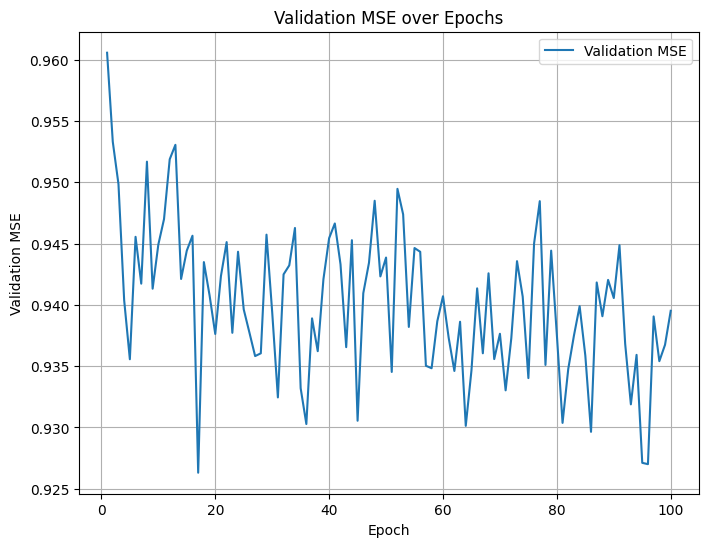

In [11]:
# Plot the change of val_mse over epochs
plt.figure(figsize=(8, 6))
plt.plot(range(1, epochs + 1), val_mse_list, label='Validation MSE')
plt.xlabel('Epoch')
plt.ylabel('Validation MSE')
plt.title('Validation MSE over Epochs')
plt.legend()
plt.grid(True)
plt.show()

<Figure size 800x1800 with 0 Axes>

<Figure size 800x1800 with 0 Axes>

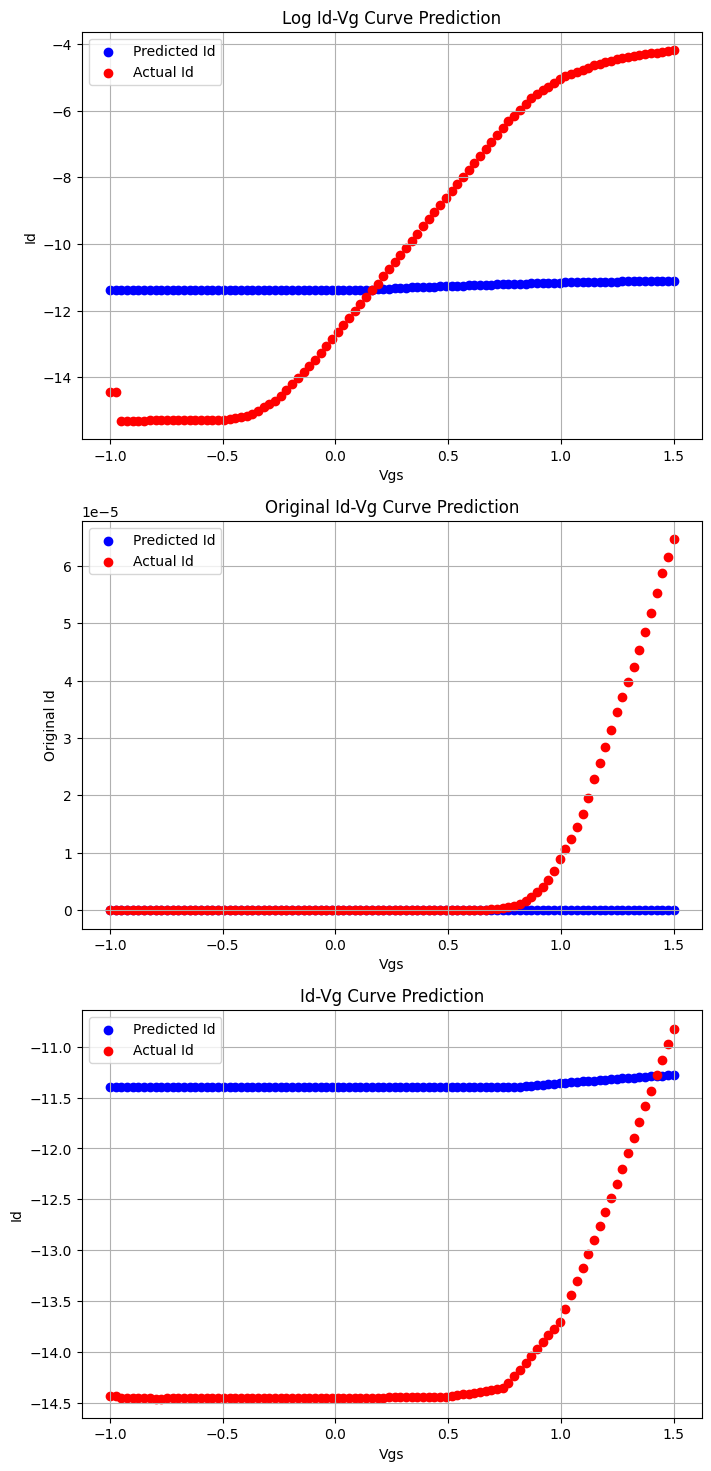

In [12]:
# Reverse the normalization process for the predictions and the actual values
y_test = np.array(y_test)
y_pred = np.array(y_pred)
y_test_original = scaler_Y.inverse_transform(y_test.reshape(-1, 1)).flatten()
y_pred_original = scaler_Y.inverse_transform(y_pred.reshape(-1, 1)).flatten()

# Generate Id-Vg diagram
Vgs_index = input_columns.index('Vgs')  # Get the index of the Vgs column
Vgs_test = scaler_X.inverse_transform(X_test)[:, Vgs_index]  # Extract the Vgs values from the test set

# Take the logarithm of the output data for the second subplot
y_test_exp = np.power(10, y_test_original)
y_pred_exp = np.power(10, y_pred_original)

# Plot the real and predicted Id-Vg curves
plt.figure(figsize=(8, 18))

# Generate Id-Vg diagram
Vgs_index = input_columns.index('Vgs')  # Get the index of the Vgs column
Vgs_test = scaler_X.inverse_transform(X_test)[:, Vgs_index]  # Extract the Vgs values from the test set

# Plot the real and predicted Id-Vg curves
plt.figure(figsize=(8, 18))

# Take the logarithm of the output data for the second subplot
y_test_exp = np.power(10,y_test_original)
y_pred_exp = np.power(10,y_pred_original)


# Plot the real and predicted Id-Vg curves
plt.figure(figsize=(8, 18))

# The difference of these three pictures are mainly different process parameters
plt.subplot(3, 1, 1)   # 3 rows and 1 column, 1st sub-picture
plt.scatter(Vgs_test[502:602], y_pred_original[502:602], label='Predicted Id', color='blue', linewidth=1)
plt.scatter(Vgs_test[502:602], y_test_original[502:602], label='Actual Id', color='red', linewidth=1)

plt.xlabel('Vgs')
plt.ylabel('Id')
plt.title('Log Id-Vg Curve Prediction')
plt.legend()
plt.grid(True)

plt.subplot(3, 1, 2) # 3 rows and 1 column, 2nd sub-picture
plt.scatter(Vgs_test[502:602], y_pred_exp[502:602], label='Predicted Id', color='blue', linewidth=1)
plt.scatter(Vgs_test[502:602], y_test_exp[502:602], label='Actual Id', color='red', linewidth=1)
plt.xlabel('Vgs')
plt.ylabel('Original Id')
plt.title('Original Id-Vg Curve Prediction')
plt.legend()
plt.grid(True)

plt.subplot(3, 1, 3) # 3 rows and 1 column, 3rd sub-picture
plt.scatter(Vgs_test[602:702], y_pred_original[602:702], label='Predicted Id', color='blue', linewidth=1)
plt.scatter(Vgs_test[602:702], y_test_original[602:702], label='Actual Id', color='red', linewidth=1)
plt.xlabel('Vgs')
plt.ylabel('Id')
plt.title('Id-Vg Curve Prediction')
plt.legend()
plt.grid(True)

plt.show()